# 🔥 NASA BASS-II (PSI-25) — Full Exploratory Data Analysis
### Burning and Suppression of Solids - II | ISS Microgravity Combustion Experiment

**129 combustion tests** conducted on the **International Space Station** to study how materials burn in microgravity.

---

## 1. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Style setup
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

# Color palette for PIs
PI_COLORS = {
    'Bhattacharjee': '#e74c3c',
    'Ferkul': '#f39c12',
    'Miller': '#2ecc71',
    'Olson': '#3498db',
    'Fernandez-Pello': '#9b59b6',
    "T'ien": '#1abc9c'
}

print('✅ Libraries loaded successfully!')

✅ Libraries loaded successfully!


In [2]:
# Load raw CSV
csv_path = r'archive (1)\PSI-25\Experimental table\PSI-25_Experimental table_BASS-II.csv'
df_raw = pd.read_csv(csv_path, encoding='utf-8')

print(f'📊 Raw dataset shape: {df_raw.shape}')
print(f'   Rows (tests): {df_raw.shape[0]}')
print(f'   Columns: {df_raw.shape[1]}')
print()
print('📋 Column names:')
for i, col in enumerate(df_raw.columns, 1):
    print(f'   {i:2d}. {col}')

📊 Raw dataset shape: (129, 17)
   Rows (tests): 129
   Columns: 17

📋 Column names:
    1. PI
    2. Test #
    3. Date
    4. GMT
    5. Sample #
    6. Fuel Sample Material
    7. Flow restrictor
    8. Fan display
    9. Air display
   10. Radiometer gain   (1000   250   50   10)
   11. Total Frames Shot
   12. Calibrated  initial O2 % by vol 
   13. Calibrated final O2 % by vol
   14. Initial CO2 % by vol
   15. Final CO2 % by vol
   16. Initial CO (ppm)
   17. Final CO (ppm)


In [3]:
# Preview raw data
print('🔍 First 10 rows (raw):')
df_raw.head(10)

🔍 First 10 rows (raw):


,PI,Test #,Date,GMT,Sample #,Fuel Sample Material,Flow restrictor,Fan display,Air display,Radiometer gain (1000 250 50 10),Total Frames Shot,Calibrated initial O2 % by vol,Calibrated final O2 % by vol,Initial CO2 % by vol,Final CO2 % by vol,Initial CO (ppm),Final CO (ppm)
0,Bhattacharjee,B1,2/19/2014,50,147,100 micron PMMA film 2 cm wide,2,62,5,50,57,22.2,22.2,0.44,0.44,0,6
1,Bhattacharjee,B2,2/19/2014,50,155,200 micron PMMA film 2 cm wide,2,62,5,50,none,22.2,1.6,0.44,NaN,6,NaN
2,Bhattacharjee,B3,2/19/2014,50,148,100 micron film 2 cm wide,2,47,2,50,253,22.2,21.8,0.43,0.49,12,19
3,Bhattacharjee,B4,2/19/2014,50,159,300 micron PMMA film 2 cm wide,2,61,5,50,137,22.2,22.2,0.44,0.51,-1,10
4,Bhattacharjee,B5,2/19/2014,50,156,200 micron 2 cm wide,2,59,5,50,206,22.2,21.9,0.43,0.43,0,12
5,Bhattacharjee,B6,7/7/2014,188,153m,2 cm 0.1 mm PMMA film,2,0.9 1.3 2.75,3 5 approaching 10,10,80,21.0,20.9,0.33,0.41,0,0.3
6,Bhattacharjee,B7,2/19/2014,50,161,400 micron film 2 cm wide,2,47,2,50,84,22.2,22.1,0.45,0.51,1,17
7,Bhattacharjee,B8,7/7/2014,188,157m,2 cm 0.2 mm PMMA film,0,1.4 incr to 10.0,10 max,10,226,21.0,20.5,0.33,0.58,0,131
8,Bhattacharjee,B9,7/7/2014,188,154m,2 cm 0.1 mm PMMA film,2,0.6 0.35,2 <1,10,45,21.0,20.9,0.33,0.35,0,10
9,Bhattacharjee,B10,7/7/2014,188,173m,1 cm 0.2 mm PMMA film,2,1.7 (52) 1.25 0.9 0.6 0.4 0.35,5 4 3 2 1,10,123,21.0,20.8,0.33,0.44,0,23


In [4]:
# Raw data types and missing values
print('📊 Raw Data Info:')
print('=' * 70)
for col in df_raw.columns:
    non_null = df_raw[col].notna().sum()
    null_count = df_raw[col].isna().sum()
    dtype = df_raw[col].dtype
    print(f'  {col:45s} | {dtype!s:8s} | {non_null:3d} valid | {null_count:2d} missing')
print('=' * 70)

📊 Raw Data Info:
  PI                                            | str      | 129 valid |  0 missing
  Test #                                        | str      | 129 valid |  0 missing
  Date                                          | str      | 129 valid |  0 missing
  GMT                                           | int64    | 129 valid |  0 missing
  Sample #                                      | str      | 129 valid |  0 missing
  Fuel Sample Material                          | str      | 129 valid |  0 missing
  Flow restrictor                               | int64    | 129 valid |  0 missing
  Fan display                                   | str      | 116 valid | 13 missing
  Air display                                   | str      | 125 valid |  4 missing
  Radiometer gain   (1000   250   50   10)      | str      | 129 valid |  0 missing
  Total Frames Shot                             | str      | 129 valid |  0 missing
  Calibrated  initial O2 % by vol               | float64  

## 2. Data Cleaning & Preprocessing

The raw data has several challenges:
- Non-numeric values in numeric columns (`none`, `OR`, `>500`, `video`)
- Multiple values in Fan/Air display columns (time-series steps)
- Inconsistent material naming
- Compound radiometer gain values (`250>50>250`)

In [5]:
# Rename columns for easier handling
df = df_raw.copy()
df.columns = [
    'PI', 'Test_ID', 'Date', 'GMT', 'Sample_No', 'Fuel_Material',
    'Flow_Restrictor', 'Fan_Display', 'Air_Display', 'Radiometer_Gain',
    'Total_Frames', 'Initial_O2_pct', 'Final_O2_pct',
    'Initial_CO2_pct', 'Final_CO2_pct', 'Initial_CO_ppm', 'Final_CO_ppm'
]

print('✅ Columns renamed.')
print(df.columns.tolist())

✅ Columns renamed.
['PI', 'Test_ID', 'Date', 'GMT', 'Sample_No', 'Fuel_Material', 'Flow_Restrictor', 'Fan_Display', 'Air_Display', 'Radiometer_Gain', 'Total_Frames', 'Initial_O2_pct', 'Final_O2_pct', 'Initial_CO2_pct', 'Final_CO2_pct', 'Initial_CO_ppm', 'Final_CO_ppm']


In [6]:
def clean_numeric(series, col_name=''):
    """Convert a messy column to numeric, tracking what couldn't be converted."""
    original = series.copy()
    # Convert to string for processing
    s = series.astype(str).str.strip()
    # Replace common non-numeric markers
    s = s.replace({'none': np.nan, 'None': np.nan, 'nan': np.nan,
                   'OR': np.nan, 'over': np.nan, 'video': np.nan})
    # Handle >500 type values — take the number
    s = s.str.replace(r'^[><]', '', regex=True)
    # Handle negative calibration offsets like -1, -2, -3 (keep as-is, they're valid)
    result = pd.to_numeric(s, errors='coerce')
    
    # Report what was lost
    lost = original[result.isna() & original.notna()]
    if len(lost) > 0 and col_name:
        print(f'  ⚠️ {col_name}: {len(lost)} values coerced to NaN')
        unique_lost = lost.unique()[:5]
        print(f'     Examples: {list(unique_lost)}')
    return result

# Clean numeric columns
print('🧹 Cleaning numeric columns...')
numeric_cols = ['Initial_O2_pct', 'Final_O2_pct', 'Initial_CO2_pct',
                'Final_CO2_pct', 'Initial_CO_ppm', 'Final_CO_ppm']

for col in numeric_cols:
    df[col] = clean_numeric(df[col], col)

# Clean Total_Frames — handle compound values
df['Total_Frames'] = clean_numeric(df['Total_Frames'], 'Total_Frames')

# Clean Flow_Restrictor
df['Flow_Restrictor'] = pd.to_numeric(df['Flow_Restrictor'], errors='coerce')

# Parse Date
df['Date'] = pd.to_datetime(df['Date'], format='mixed', dayfirst=False, errors='coerce')

print('\n✅ Numeric cleaning complete!')

🧹 Cleaning numeric columns...
  ⚠️ Final_O2_pct: 2 values coerced to NaN
     Examples: ['none']
  ⚠️ Initial_CO2_pct: 2 values coerced to NaN
     Examples: ['none']
  ⚠️ Final_CO2_pct: 5 values coerced to NaN
     Examples: ['none']
  ⚠️ Initial_CO_ppm: 3 values coerced to NaN
     Examples: ['OR', 'none']
  ⚠️ Final_CO_ppm: 7 values coerced to NaN
     Examples: ['none', 'OR', 'over']
  ⚠️ Total_Frames: 6 values coerced to NaN
     Examples: ['none', '300+   +102', '10 postburn only', 'video']

✅ Numeric cleaning complete!


In [7]:
# Create derived columns

# O2 consumed (decrease)
df['O2_Consumed_pct'] = df['Initial_O2_pct'] - df['Final_O2_pct']

# CO2 produced (increase)
df['CO2_Produced_pct'] = df['Final_CO2_pct'] - df['Initial_CO2_pct']

# CO produced (increase)
df['CO_Produced_ppm'] = df['Final_CO_ppm'] - df['Initial_CO_ppm']

# Classify fuel material into broad categories
def classify_material(mat):
    mat_lower = str(mat).lower()
    if 'film' in mat_lower or ('micron' in mat_lower and 'mm' not in mat_lower and 'rod' not in mat_lower):
        return 'PMMA Film'
    elif 'rod' in mat_lower:
        return 'PMMA Rod'
    elif 'slab' in mat_lower or ('mm' in mat_lower and 'thick' in mat_lower and 'rod' not in mat_lower) or \
         ('mm thick' in mat_lower):
        return 'PMMA Slab'
    elif 'sibal' in mat_lower:
        return 'SIBAL'
    elif 'nomex' in mat_lower:
        return 'Nomex Fabric'
    elif 'wax' in mat_lower or 'candle' in mat_lower:
        return 'Wax Candle'
    elif 'spherical' in mat_lower:
        return 'Spherical Section'
    elif 'pmma' in mat_lower:
        return 'PMMA Slab'  # default for PMMA with mm thickness
    else:
        return 'Other'

df['Material_Category'] = df['Fuel_Material'].apply(classify_material)

# Extract fuel width/thickness where possible
import re

def extract_thickness_mm(mat):
    """Try to extract thickness in mm."""
    mat = str(mat).lower()
    # "X micron" or "X μm" -> convert to mm
    m = re.search(r'(\d+)\s*micron', mat)
    if m:
        return int(m.group(1)) / 1000
    # "X.X mm" or "X mm"
    m = re.search(r'([\d.]+)\s*mm\s*(?:thick|pmma|film)?', mat)
    if m:
        return float(m.group(1))
    # Rod diameters: 1/4", 3/8", 1/2" -> convert to mm
    fractions = {'1/4': 6.35, '3/8': 9.525, '1/2': 12.7, '0.5': 12.7}
    for frac, mm_val in fractions.items():
        if frac in mat and ('rod' in mat or '"' in mat):
            return mm_val
    return np.nan

df['Thickness_mm'] = df['Fuel_Material'].apply(extract_thickness_mm)

# Danger level based on final CO
def co_danger(co_ppm):
    if pd.isna(co_ppm):
        return 'Unknown'
    elif co_ppm < 50:
        return '🟢 Low (<50 ppm)'
    elif co_ppm < 200:
        return '🟡 Moderate (50-200)'
    elif co_ppm < 500:
        return '🟠 High (200-500)'
    else:
        return '🔴 Dangerous (500+)'

df['CO_Danger_Level'] = df['Final_CO_ppm'].apply(co_danger)

print('✅ Derived columns created:')
print('   - O2_Consumed_pct (O2 decrease)')
print('   - CO2_Produced_pct (CO2 increase)')
print('   - CO_Produced_ppm (CO increase)')
print('   - Material_Category (broad fuel type)')
print('   - Thickness_mm (fuel thickness in mm)')
print('   - CO_Danger_Level (safety classification)')

✅ Derived columns created:
   - O2_Consumed_pct (O2 decrease)
   - CO2_Produced_pct (CO2 increase)
   - CO_Produced_ppm (CO increase)
   - Material_Category (broad fuel type)
   - Thickness_mm (fuel thickness in mm)
   - CO_Danger_Level (safety classification)


In [8]:
# Preview cleaned data
print('🔍 Cleaned dataset preview:')
df[['PI', 'Test_ID', 'Date', 'Material_Category', 'Thickness_mm', 'Flow_Restrictor',
    'Initial_O2_pct', 'Final_O2_pct', 'O2_Consumed_pct',
    'CO2_Produced_pct', 'CO_Produced_ppm', 'CO_Danger_Level']].head(15)

🔍 Cleaned dataset preview:


,PI,Test_ID,Date,Material_Category,Thickness_mm,Flow_Restrictor,Initial_O2_pct,Final_O2_pct,O2_Consumed_pct,CO2_Produced_pct,CO_Produced_ppm,CO_Danger_Level
0,Bhattacharjee,B1,2014-02-19,PMMA Film,0.1,2,22.2,22.2,0.0,0.00,6.0,🟢 Low (<50 ppm)
1,Bhattacharjee,B2,2014-02-19,PMMA Film,0.2,2,22.2,1.6,20.6,NaN,NaN,Unknown
2,Bhattacharjee,B3,2014-02-19,PMMA Film,0.1,2,22.2,21.8,0.4,0.06,7.0,🟢 Low (<50 ppm)
3,Bhattacharjee,B4,2014-02-19,PMMA Film,0.3,2,22.2,22.2,0.0,0.07,11.0,🟢 Low (<50 ppm)
4,Bhattacharjee,B5,2014-02-19,PMMA Film,0.2,2,22.2,21.9,0.3,0.00,12.0,🟢 Low (<50 ppm)
5,Bhattacharjee,B6,2014-07-07,PMMA Film,0.1,2,21.0,20.9,0.1,0.08,0.3,🟢 Low (<50 ppm)
6,Bhattacharjee,B7,2014-02-19,PMMA Film,0.4,2,22.2,22.1,0.1,0.06,16.0,🟢 Low (<50 ppm)
7,Bhattacharjee,B8,2014-07-07,PMMA Film,0.2,0,21.0,20.5,0.5,0.25,131.0,🟡 Moderate (50-200)
8,Bhattacharjee,B9,2014-07-07,PMMA Film,0.1,2,21.0,20.9,0.1,0.02,10.0,🟢 Low (<50 ppm)
9,Bhattacharjee,B10,2014-07-07,PMMA Film,0.2,2,21.0,20.8,0.2,0.11,23.0,🟢 Low (<50 ppm)


## 3. Dataset Overview Statistics

In [9]:
print('=' * 60)
print('       📊 BASS-II DATASET OVERVIEW')
print('=' * 60)
print(f'  Total tests:              {len(df)}')
print(f'  Number of PIs:            {df["PI"].nunique()}')
print(f'  Date range:               {df["Date"].min().strftime("%b %d, %Y")} → {df["Date"].max().strftime("%b %d, %Y")}')
print(f'  Material categories:      {df["Material_Category"].nunique()}')
print(f'  O₂ range:                 {df["Initial_O2_pct"].min():.1f}% → {df["Initial_O2_pct"].max():.1f}%')
print(f'  Max CO₂ produced:         {df["CO2_Produced_pct"].max():.2f}%')
print(f'  Max CO (final):           {df["Final_CO_ppm"].max():.0f} ppm')
print(f'  Flow restrictor values:   {sorted(df["Flow_Restrictor"].dropna().unique().astype(int))}')
print('=' * 60)
print()

# Descriptive stats for key numeric columns
key_cols = ['Initial_O2_pct', 'Final_O2_pct', 'O2_Consumed_pct',
            'Initial_CO2_pct', 'CO2_Produced_pct',
            'Initial_CO_ppm', 'Final_CO_ppm', 'CO_Produced_ppm',
            'Total_Frames', 'Thickness_mm']
df[key_cols].describe().round(2)

       📊 BASS-II DATASET OVERVIEW
  Total tests:              129
  Number of PIs:            6
  Date range:               Feb 14, 2014 → Jun 24, 2018
  Material categories:      7
  O₂ range:                 13.6% → 22.2%
  Max CO₂ produced:         2.78%
  Max CO (final):           950 ppm
  Flow restrictor values:   [np.int64(0), np.int64(1), np.int64(2)]



,Initial_O2_pct,Final_O2_pct,O2_Consumed_pct,Initial_CO2_pct,CO2_Produced_pct,Initial_CO_ppm,Final_CO_ppm,CO_Produced_ppm,Total_Frames,Thickness_mm
count,129.00,127.00,127.00,127.00,121.00,126.00,121.00,119.00,123.00,96.00
mean,18.57,17.93,0.64,0.52,0.39,70.64,195.94,132.94,165.89,5.30
std,2.29,4.37,3.98,0.36,0.46,150.73,218.61,165.36,91.91,3.97
min,13.60,0.60,-19.70,0.00,-0.01,-3.00,0.30,-23.00,2.00,0.10
25%,17.00,16.60,0.10,0.32,0.04,0.00,34.00,17.00,85.00,1.00
50%,18.20,17.40,0.30,0.41,0.24,5.50,94.00,46.00,156.00,6.35
75%,20.80,20.10,0.75,0.52,0.62,58.50,322.00,206.00,254.50,6.35
max,22.20,40.40,20.60,1.85,2.78,950.00,950.00,575.00,316.00,12.70


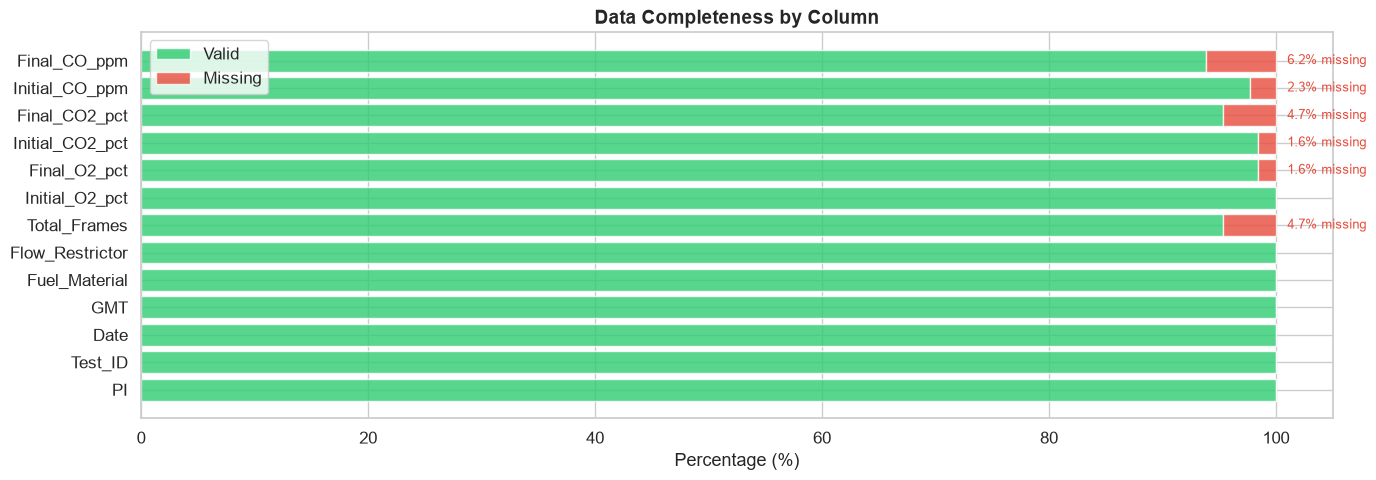

In [10]:
# Missing data overview
fig, ax = plt.subplots(figsize=(14, 5))

cols_to_check = ['PI', 'Test_ID', 'Date', 'GMT', 'Fuel_Material', 'Flow_Restrictor',
                 'Total_Frames', 'Initial_O2_pct', 'Final_O2_pct',
                 'Initial_CO2_pct', 'Final_CO2_pct', 'Initial_CO_ppm', 'Final_CO_ppm']

missing_pct = df[cols_to_check].isnull().mean() * 100
valid_pct = 100 - missing_pct

bars = ax.barh(range(len(cols_to_check)), valid_pct, color='#2ecc71', alpha=0.8, label='Valid')
ax.barh(range(len(cols_to_check)), missing_pct, left=valid_pct, color='#e74c3c', alpha=0.8, label='Missing')
ax.set_yticks(range(len(cols_to_check)))
ax.set_yticklabels(cols_to_check)
ax.set_xlabel('Percentage (%)')
ax.set_title('Data Completeness by Column')
ax.legend()
ax.set_xlim(0, 105)

for i, (v, m) in enumerate(zip(valid_pct, missing_pct)):
    if m > 0:
        ax.text(101, i, f'{m:.1f}% missing', va='center', fontsize=9, color='#e74c3c')

plt.tight_layout()
plt.show()

## 4. PI (Investigator) Analysis

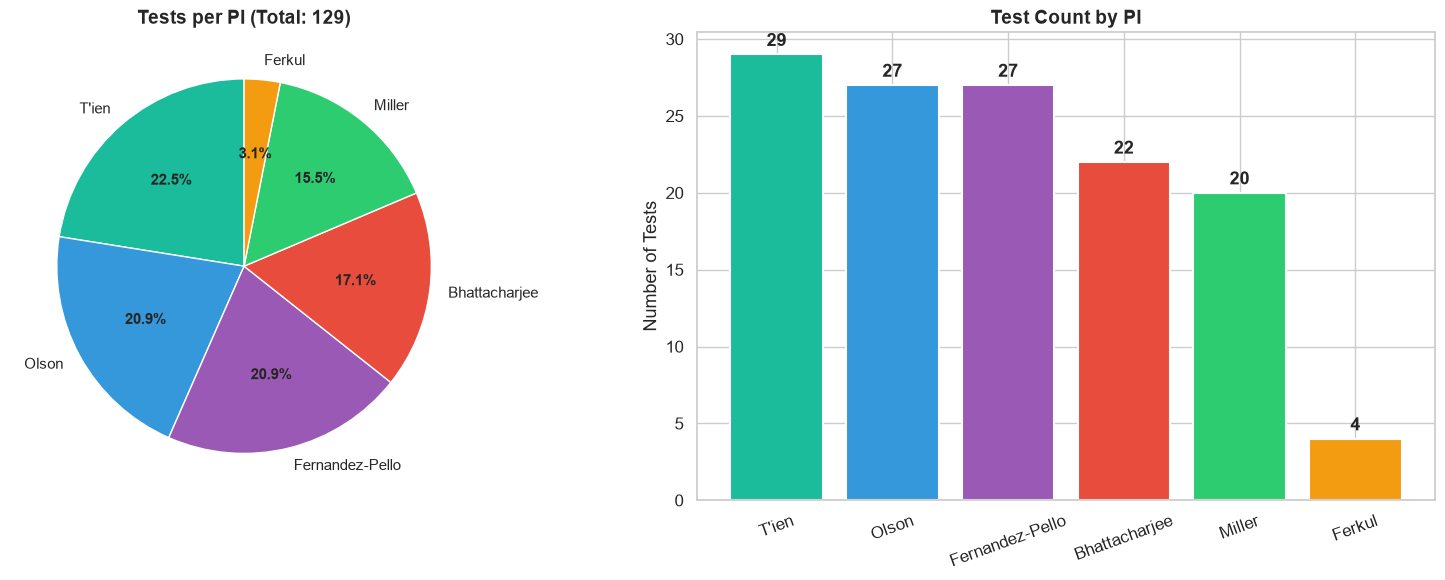

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Pie chart: Test count by PI ---
pi_counts = df['PI'].value_counts()
colors = [PI_COLORS.get(pi, '#95a5a6') for pi in pi_counts.index]
wedges, texts, autotexts = axes[0].pie(
    pi_counts, labels=pi_counts.index, autopct='%1.1f%%',
    colors=colors, startangle=90, textprops={'fontsize': 11}
)
for t in autotexts:
    t.set_fontweight('bold')
axes[0].set_title(f'Tests per PI (Total: {len(df)})')

# --- Bar chart: Test count with numbers ---
bars = axes[1].bar(pi_counts.index, pi_counts.values, color=colors, edgecolor='white', linewidth=1.5)
for bar, count in zip(bars, pi_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                str(count), ha='center', va='bottom', fontweight='bold', fontsize=13)
axes[1].set_ylabel('Number of Tests')
axes[1].set_title('Test Count by PI')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

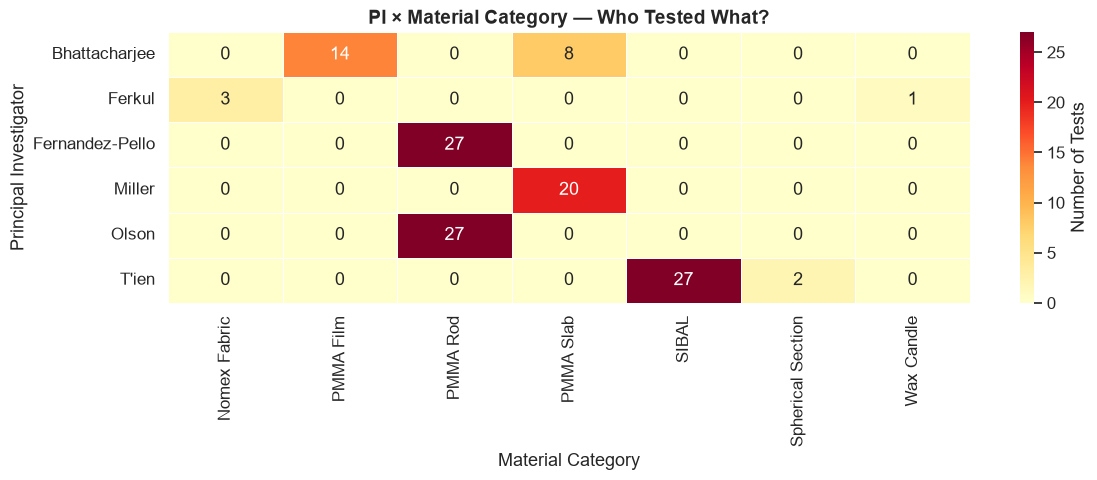

In [12]:
# PI vs Material Category heatmap
ct = pd.crosstab(df['PI'], df['Material_Category'])

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(ct, annot=True, fmt='d', cmap='YlOrRd', linewidths=0.5,
            linecolor='white', ax=ax, cbar_kws={'label': 'Number of Tests'})
ax.set_title('PI × Material Category — Who Tested What?')
ax.set_xlabel('Material Category')
ax.set_ylabel('Principal Investigator')
plt.tight_layout()
plt.show()

## 5. Material Analysis

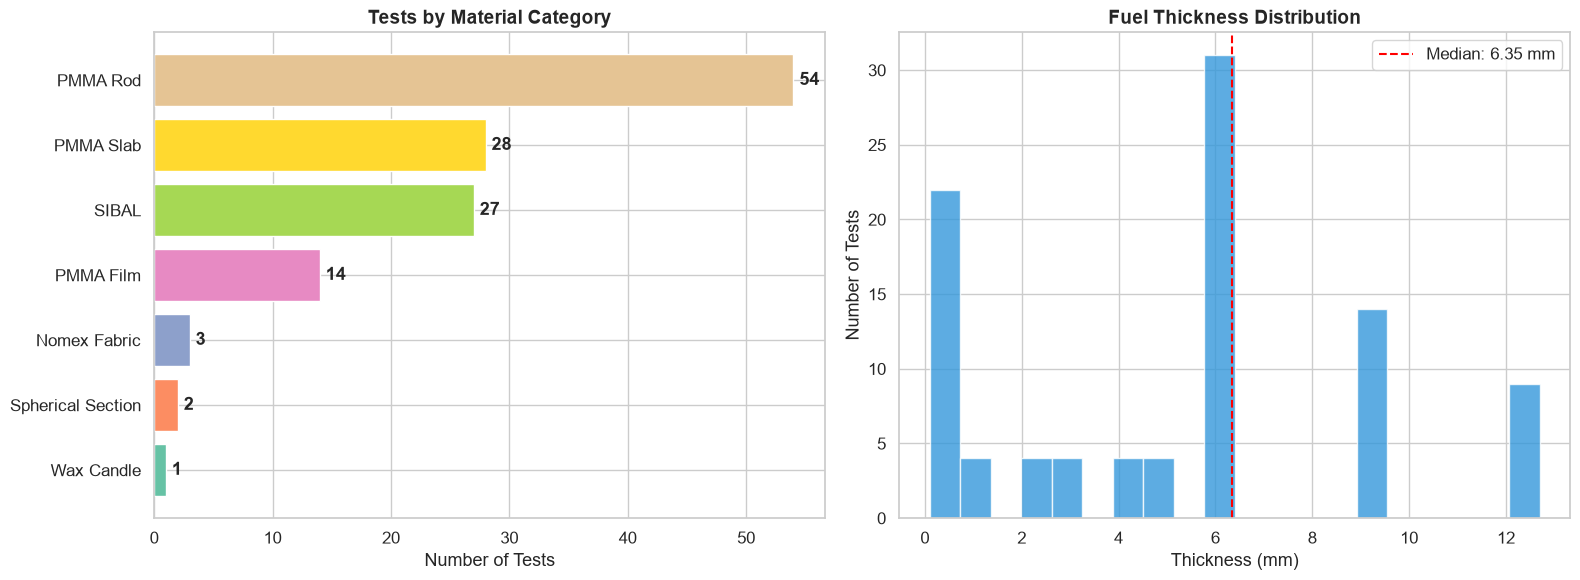

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Material category distribution
mat_counts = df['Material_Category'].value_counts()
mat_colors = sns.color_palette('Set2', len(mat_counts))
bars = axes[0].barh(mat_counts.index[::-1], mat_counts.values[::-1],
                     color=mat_colors[:len(mat_counts)])
for bar, count in zip(bars, mat_counts.values[::-1]):
    axes[0].text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                str(count), va='center', fontweight='bold')
axes[0].set_xlabel('Number of Tests')
axes[0].set_title('Tests by Material Category')

# Thickness distribution
thickness_data = df.dropna(subset=['Thickness_mm'])
axes[1].hist(thickness_data['Thickness_mm'], bins=20, color='#3498db',
             edgecolor='white', alpha=0.8)
axes[1].set_xlabel('Thickness (mm)')
axes[1].set_ylabel('Number of Tests')
axes[1].set_title('Fuel Thickness Distribution')
axes[1].axvline(thickness_data['Thickness_mm'].median(), color='red',
                linestyle='--', label=f'Median: {thickness_data["Thickness_mm"].median():.2f} mm')
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Oxygen (O₂) Analysis

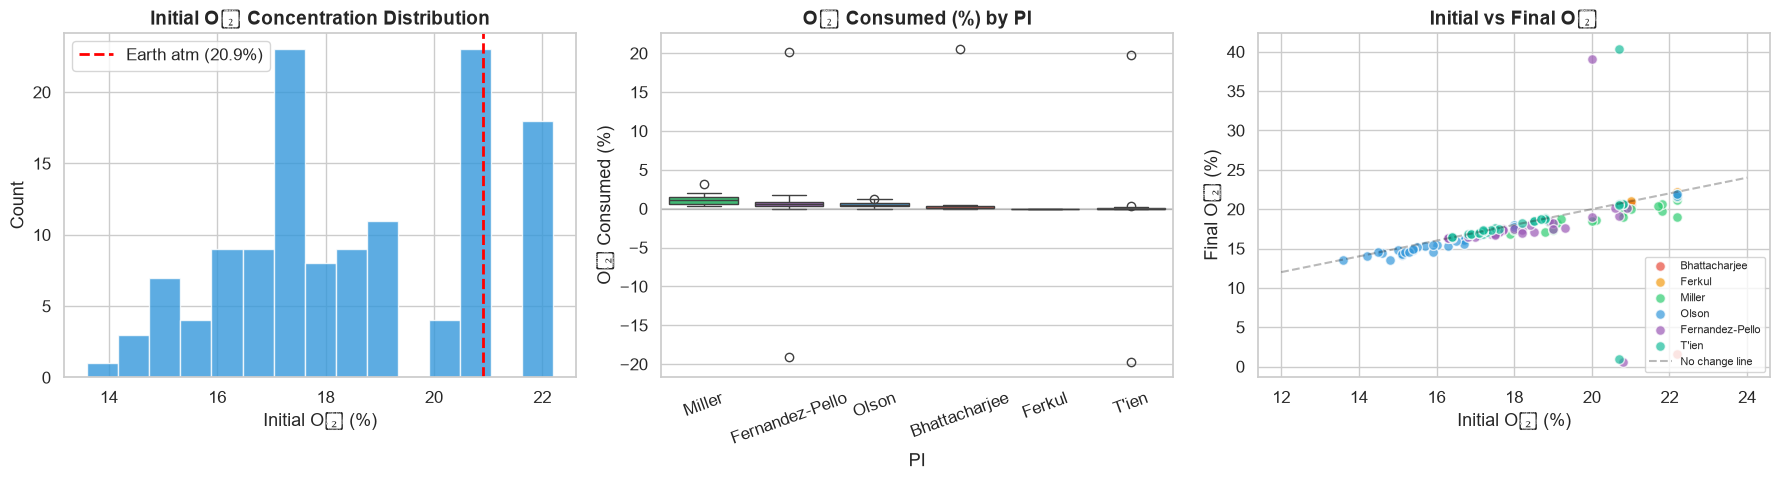

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Initial O2 distribution
axes[0].hist(df['Initial_O2_pct'].dropna(), bins=15, color='#3498db',
             edgecolor='white', alpha=0.8)
axes[0].axvline(20.9, color='red', linestyle='--', linewidth=2, label='Earth atm (20.9%)')
axes[0].set_xlabel('Initial O₂ (%)')
axes[0].set_ylabel('Count')
axes[0].set_title('Initial O₂ Concentration Distribution')
axes[0].legend()

# O2 consumed by PI
o2_data = df.dropna(subset=['O2_Consumed_pct'])
pi_order = o2_data.groupby('PI')['O2_Consumed_pct'].median().sort_values(ascending=False).index
sns.boxplot(data=o2_data, x='PI', y='O2_Consumed_pct', order=pi_order,
            palette=PI_COLORS, ax=axes[1])
axes[1].set_title('O₂ Consumed (%) by PI')
axes[1].set_ylabel('O₂ Consumed (%)')
axes[1].tick_params(axis='x', rotation=20)
axes[1].axhline(0, color='gray', linestyle='-', alpha=0.3)

# Initial vs Final O2 scatter
for pi in df['PI'].unique():
    mask = df['PI'] == pi
    axes[2].scatter(df.loc[mask, 'Initial_O2_pct'], df.loc[mask, 'Final_O2_pct'],
                    c=PI_COLORS.get(pi, 'gray'), label=pi, s=50, alpha=0.7, edgecolors='white')

# Add y=x line (no change)
lims = [12, 24]
axes[2].plot(lims, lims, 'k--', alpha=0.3, label='No change line')
axes[2].set_xlabel('Initial O₂ (%)')
axes[2].set_ylabel('Final O₂ (%)')
axes[2].set_title('Initial vs Final O₂')
axes[2].legend(fontsize=8, loc='lower right')

plt.tight_layout()
plt.show()

## 7. CO₂ Production Analysis

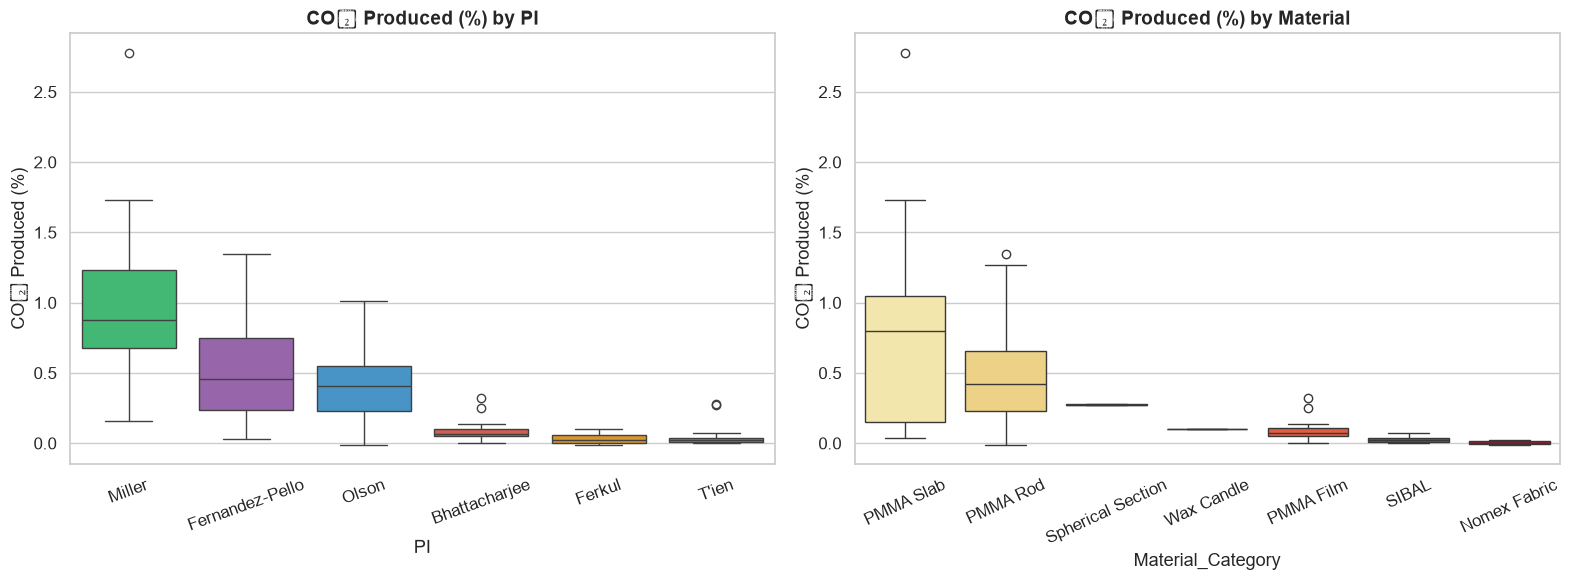

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# CO2 produced by PI
co2_data = df.dropna(subset=['CO2_Produced_pct'])
pi_order = co2_data.groupby('PI')['CO2_Produced_pct'].median().sort_values(ascending=False).index
sns.boxplot(data=co2_data, x='PI', y='CO2_Produced_pct', order=pi_order,
            palette=PI_COLORS, ax=axes[0])
axes[0].set_title('CO₂ Produced (%) by PI')
axes[0].set_ylabel('CO₂ Produced (%)')
axes[0].tick_params(axis='x', rotation=20)

# CO2 produced by Material
mat_order = co2_data.groupby('Material_Category')['CO2_Produced_pct'].median().sort_values(ascending=False).index
sns.boxplot(data=co2_data, x='Material_Category', y='CO2_Produced_pct',
            order=mat_order, palette='YlOrRd', ax=axes[1])
axes[1].set_title('CO₂ Produced (%) by Material')
axes[1].set_ylabel('CO₂ Produced (%)')
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

## 8. ⚠️ CO (Carbon Monoxide) Safety Analysis — Most Critical!

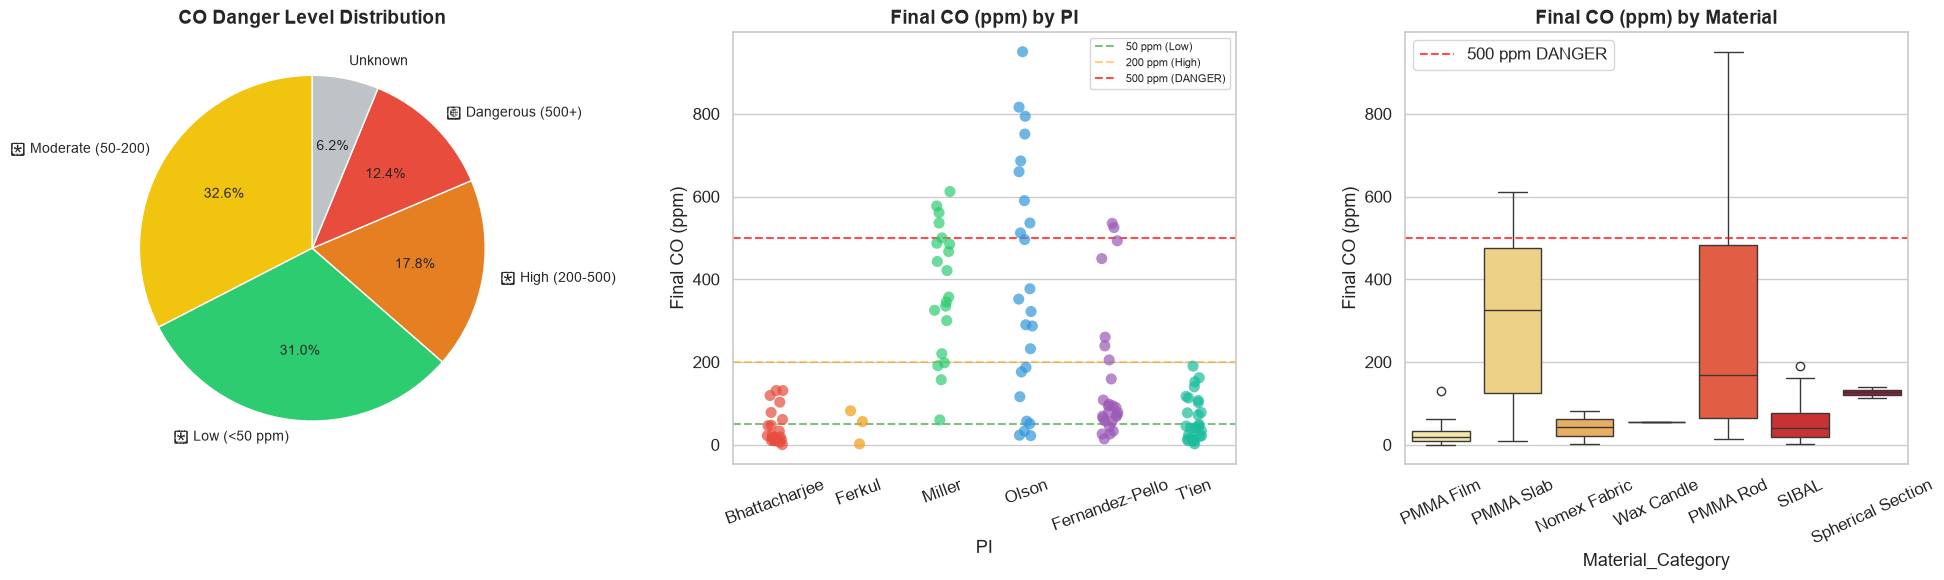

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# --- 1. CO Danger Level pie ---
danger_counts = df['CO_Danger_Level'].value_counts()
danger_colors = {
    '🟢 Low (<50 ppm)': '#2ecc71',
    '🟡 Moderate (50-200)': '#f1c40f',
    '🟠 High (200-500)': '#e67e22',
    '🔴 Dangerous (500+)': '#e74c3c',
    'Unknown': '#bdc3c7'
}
colors = [danger_colors.get(d, '#95a5a6') for d in danger_counts.index]
axes[0].pie(danger_counts, labels=danger_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90, textprops={'fontsize': 10})
axes[0].set_title('CO Danger Level Distribution')

# --- 2. Final CO by PI ---
co_data = df.dropna(subset=['Final_CO_ppm'])
sns.stripplot(data=co_data, x='PI', y='Final_CO_ppm', palette=PI_COLORS,
              size=8, alpha=0.7, jitter=True, ax=axes[1])
axes[1].axhline(50, color='green', linestyle='--', alpha=0.5, label='50 ppm (Low)')
axes[1].axhline(200, color='orange', linestyle='--', alpha=0.5, label='200 ppm (High)')
axes[1].axhline(500, color='red', linestyle='--', alpha=0.7, label='500 ppm (DANGER)')
axes[1].set_title('Final CO (ppm) by PI')
axes[1].set_ylabel('Final CO (ppm)')
axes[1].legend(fontsize=8)
axes[1].tick_params(axis='x', rotation=20)

# --- 3. Final CO by Material ---
sns.boxplot(data=co_data, x='Material_Category', y='Final_CO_ppm',
            palette='YlOrRd', ax=axes[2])
axes[2].axhline(500, color='red', linestyle='--', alpha=0.7, label='500 ppm DANGER')
axes[2].set_title('Final CO (ppm) by Material')
axes[2].set_ylabel('Final CO (ppm)')
axes[2].legend()
axes[2].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

In [17]:
# Top 15 most dangerous tests by CO production
print('🚨 TOP 15 MOST DANGEROUS TESTS (by Final CO):')
print('=' * 90)
top_co = df.nlargest(15, 'Final_CO_ppm')[[
    'PI', 'Test_ID', 'Material_Category', 'Initial_O2_pct',
    'Final_CO_ppm', 'CO2_Produced_pct', 'CO_Danger_Level'
]].reset_index(drop=True)
top_co.index = top_co.index + 1
top_co

🚨 TOP 15 MOST DANGEROUS TESTS (by Final CO):


,PI,Test_ID,Material_Category,Initial_O2_pct,Final_CO_ppm,CO2_Produced_pct,CO_Danger_Level
1,Olson,O13a,PMMA Rod,15.9,950.0,0.94,🔴 Dangerous (500+)
2,Olson,O18,PMMA Rod,15.2,816.0,0.49,🔴 Dangerous (500+)
3,Olson,O9,PMMA Rod,15.0,794.0,0.22,🔴 Dangerous (500+)
4,Olson,O15b,PMMA Rod,16.7,751.0,1.01,🔴 Dangerous (500+)
5,Olson,O19,PMMA Rod,15.3,686.0,0.65,🔴 Dangerous (500+)
6,Olson,O8b,PMMA Rod,15.5,660.0,0.30,🔴 Dangerous (500+)
7,Miller,M7,PMMA Slab,18.9,612.0,0.42,🔴 Dangerous (500+)
8,Olson,O5b,PMMA Rod,14.2,590.0,0.09,🔴 Dangerous (500+)
9,Miller,M11,PMMA Slab,20.0,577.0,1.10,🔴 Dangerous (500+)
10,Miller,M4,PMMA Slab,21.8,561.0,1.73,🔴 Dangerous (500+)


## 9. O₂ vs CO₂ vs CO — Combustion Relationship

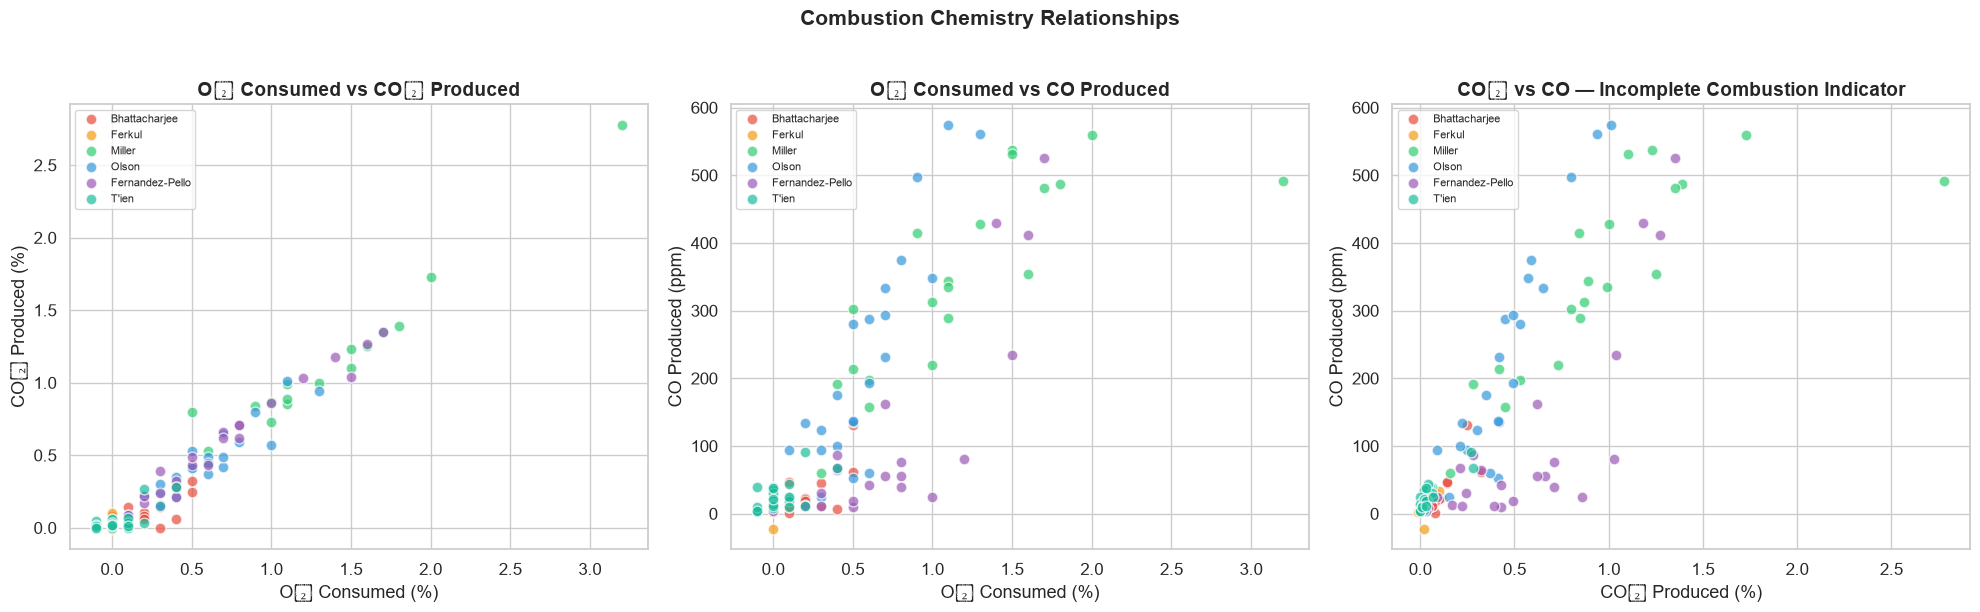

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

plot_data = df.dropna(subset=['O2_Consumed_pct', 'CO2_Produced_pct', 'CO_Produced_ppm'])

# --- 1. O2 consumed vs CO2 produced ---
for pi in plot_data['PI'].unique():
    mask = plot_data['PI'] == pi
    axes[0].scatter(plot_data.loc[mask, 'O2_Consumed_pct'],
                    plot_data.loc[mask, 'CO2_Produced_pct'],
                    c=PI_COLORS.get(pi, 'gray'), label=pi, s=60, alpha=0.7, edgecolors='white')
axes[0].set_xlabel('O₂ Consumed (%)')
axes[0].set_ylabel('CO₂ Produced (%)')
axes[0].set_title('O₂ Consumed vs CO₂ Produced')
axes[0].legend(fontsize=8)

# --- 2. O2 consumed vs CO produced ---
for pi in plot_data['PI'].unique():
    mask = plot_data['PI'] == pi
    axes[1].scatter(plot_data.loc[mask, 'O2_Consumed_pct'],
                    plot_data.loc[mask, 'CO_Produced_ppm'],
                    c=PI_COLORS.get(pi, 'gray'), label=pi, s=60, alpha=0.7, edgecolors='white')
axes[1].set_xlabel('O₂ Consumed (%)')
axes[1].set_ylabel('CO Produced (ppm)')
axes[1].set_title('O₂ Consumed vs CO Produced')
axes[1].legend(fontsize=8)

# --- 3. CO2 produced vs CO produced ---
for pi in plot_data['PI'].unique():
    mask = plot_data['PI'] == pi
    axes[2].scatter(plot_data.loc[mask, 'CO2_Produced_pct'],
                    plot_data.loc[mask, 'CO_Produced_ppm'],
                    c=PI_COLORS.get(pi, 'gray'), label=pi, s=60, alpha=0.7, edgecolors='white')
axes[2].set_xlabel('CO₂ Produced (%)')
axes[2].set_ylabel('CO Produced (ppm)')
axes[2].set_title('CO₂ vs CO — Incomplete Combustion Indicator')
axes[2].legend(fontsize=8)

plt.suptitle('Combustion Chemistry Relationships', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 10. Flow Restrictor Impact

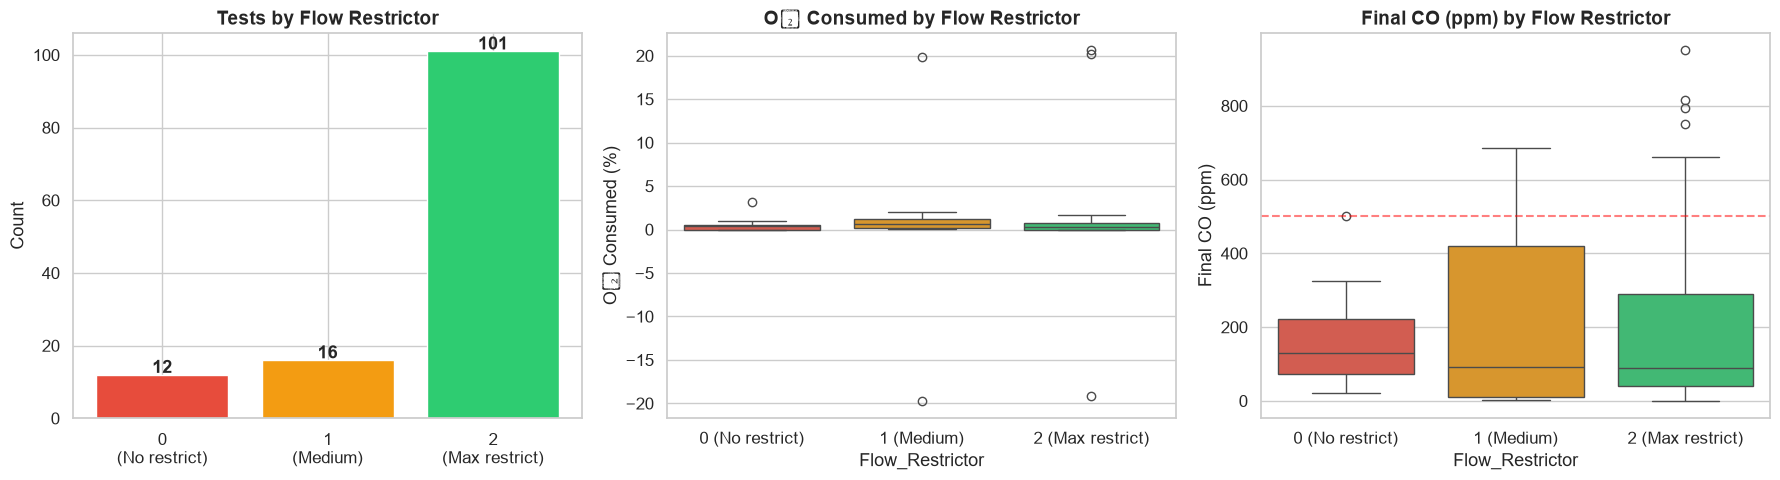

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

fr_data = df.dropna(subset=['Flow_Restrictor'])
fr_data['Flow_Restrictor_Label'] = fr_data['Flow_Restrictor'].map(
    {0: '0 (No restrict)', 1: '1 (Medium)', 2: '2 (Max restrict)'}
)

# Count by restrictor
fr_counts = fr_data['Flow_Restrictor'].value_counts().sort_index()
axes[0].bar(['0\n(No restrict)', '1\n(Medium)', '2\n(Max restrict)'],
            [fr_counts.get(0, 0), fr_counts.get(1, 0), fr_counts.get(2, 0)],
            color=['#e74c3c', '#f39c12', '#2ecc71'], edgecolor='white')
for i, v in enumerate([fr_counts.get(0, 0), fr_counts.get(1, 0), fr_counts.get(2, 0)]):
    axes[0].text(i, v + 0.5, str(v), ha='center', fontweight='bold', fontsize=13)
axes[0].set_title('Tests by Flow Restrictor')
axes[0].set_ylabel('Count')

# O2 consumed by restrictor
sns.boxplot(data=fr_data, x='Flow_Restrictor', y='O2_Consumed_pct',
            palette=['#e74c3c', '#f39c12', '#2ecc71'], ax=axes[1])
axes[1].set_xticklabels(['0 (No restrict)', '1 (Medium)', '2 (Max restrict)'])
axes[1].set_title('O₂ Consumed by Flow Restrictor')
axes[1].set_ylabel('O₂ Consumed (%)')

# CO by restrictor
sns.boxplot(data=fr_data, x='Flow_Restrictor', y='Final_CO_ppm',
            palette=['#e74c3c', '#f39c12', '#2ecc71'], ax=axes[2])
axes[2].set_xticklabels(['0 (No restrict)', '1 (Medium)', '2 (Max restrict)'])
axes[2].set_title('Final CO (ppm) by Flow Restrictor')
axes[2].set_ylabel('Final CO (ppm)')
axes[2].axhline(500, color='red', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 11. Thickness vs Combustion Intensity

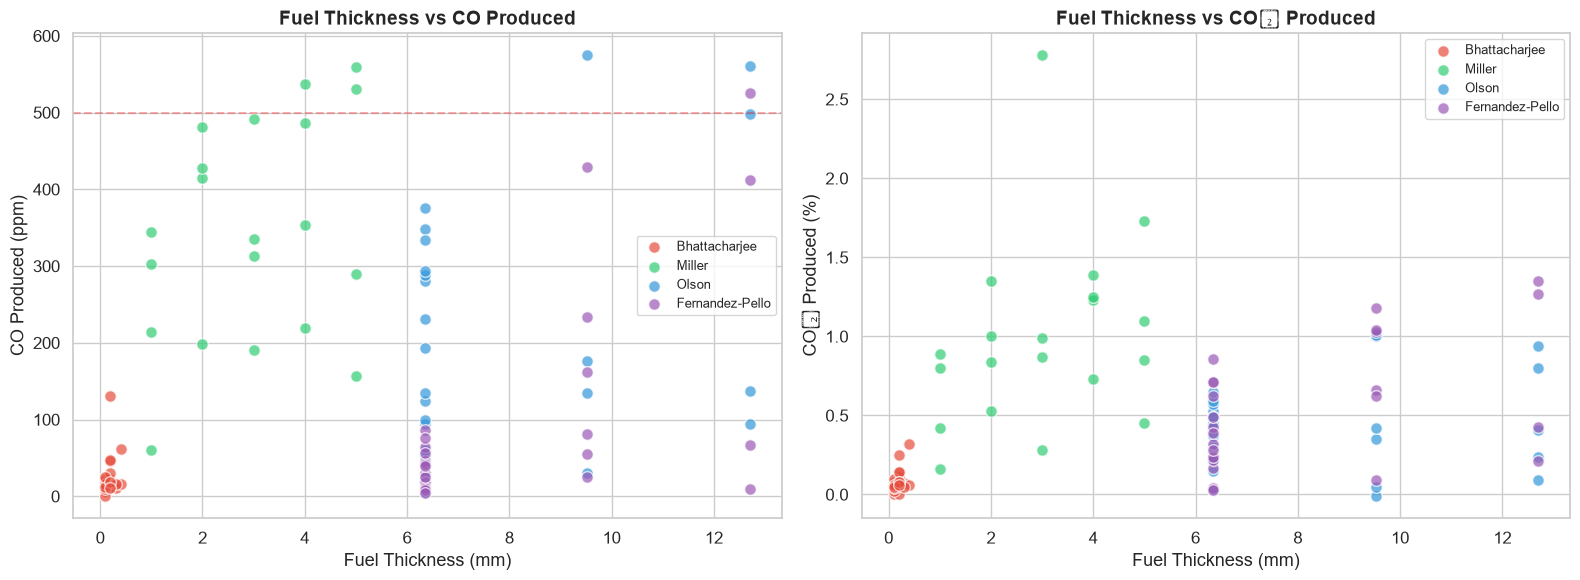

In [20]:
thick_data = df.dropna(subset=['Thickness_mm', 'CO_Produced_ppm'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Thickness vs CO produced
for pi in thick_data['PI'].unique():
    mask = thick_data['PI'] == pi
    axes[0].scatter(thick_data.loc[mask, 'Thickness_mm'],
                    thick_data.loc[mask, 'CO_Produced_ppm'],
                    c=PI_COLORS.get(pi, 'gray'), label=pi, s=70, alpha=0.7, edgecolors='white')
axes[0].set_xlabel('Fuel Thickness (mm)')
axes[0].set_ylabel('CO Produced (ppm)')
axes[0].set_title('Fuel Thickness vs CO Produced')
axes[0].legend(fontsize=9)
axes[0].axhline(500, color='red', linestyle='--', alpha=0.3)

# Thickness vs CO2 produced
thick_data2 = df.dropna(subset=['Thickness_mm', 'CO2_Produced_pct'])
for pi in thick_data2['PI'].unique():
    mask = thick_data2['PI'] == pi
    axes[1].scatter(thick_data2.loc[mask, 'Thickness_mm'],
                    thick_data2.loc[mask, 'CO2_Produced_pct'],
                    c=PI_COLORS.get(pi, 'gray'), label=pi, s=70, alpha=0.7, edgecolors='white')
axes[1].set_xlabel('Fuel Thickness (mm)')
axes[1].set_ylabel('CO₂ Produced (%)')
axes[1].set_title('Fuel Thickness vs CO₂ Produced')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

## 12. Temporal Analysis — When Were Tests Conducted?

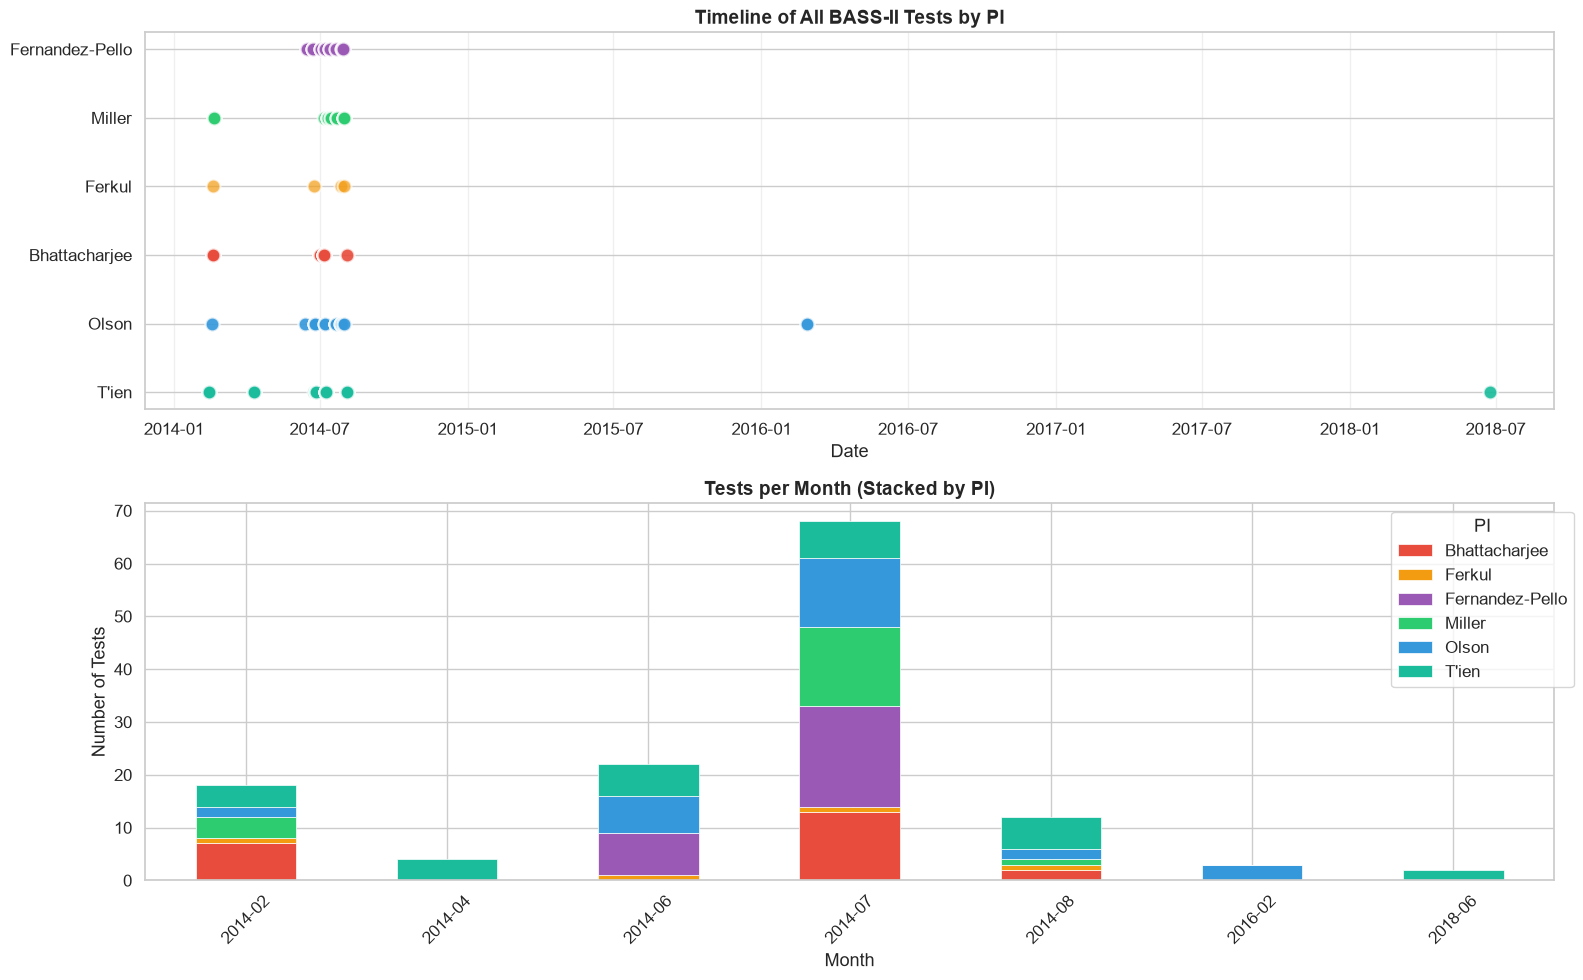

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# --- Timeline of tests ---
date_data = df.dropna(subset=['Date']).sort_values('Date')

for i, pi in enumerate(date_data['PI'].unique()):
    mask = date_data['PI'] == pi
    y_vals = [i] * mask.sum()
    axes[0].scatter(date_data.loc[mask, 'Date'], y_vals,
                    c=PI_COLORS.get(pi, 'gray'), label=pi, s=100, alpha=0.7,
                    edgecolors='white', linewidth=1.5, zorder=3)

axes[0].set_yticks(range(len(date_data['PI'].unique())))
axes[0].set_yticklabels(date_data['PI'].unique())
axes[0].set_xlabel('Date')
axes[0].set_title('Timeline of All BASS-II Tests by PI')
axes[0].grid(axis='x', alpha=0.3)

# --- Tests per month ---
date_data['YearMonth'] = date_data['Date'].dt.to_period('M')
monthly = date_data.groupby(['YearMonth', 'PI']).size().unstack(fill_value=0)
monthly.index = monthly.index.astype(str)
monthly.plot(kind='bar', stacked=True, ax=axes[1],
             color=[PI_COLORS.get(pi, 'gray') for pi in monthly.columns],
             edgecolor='white', linewidth=0.5)
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Number of Tests')
axes[1].set_title('Tests per Month (Stacked by PI)')
axes[1].legend(title='PI', bbox_to_anchor=(1.02, 1))
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 13. Correlation Heatmap

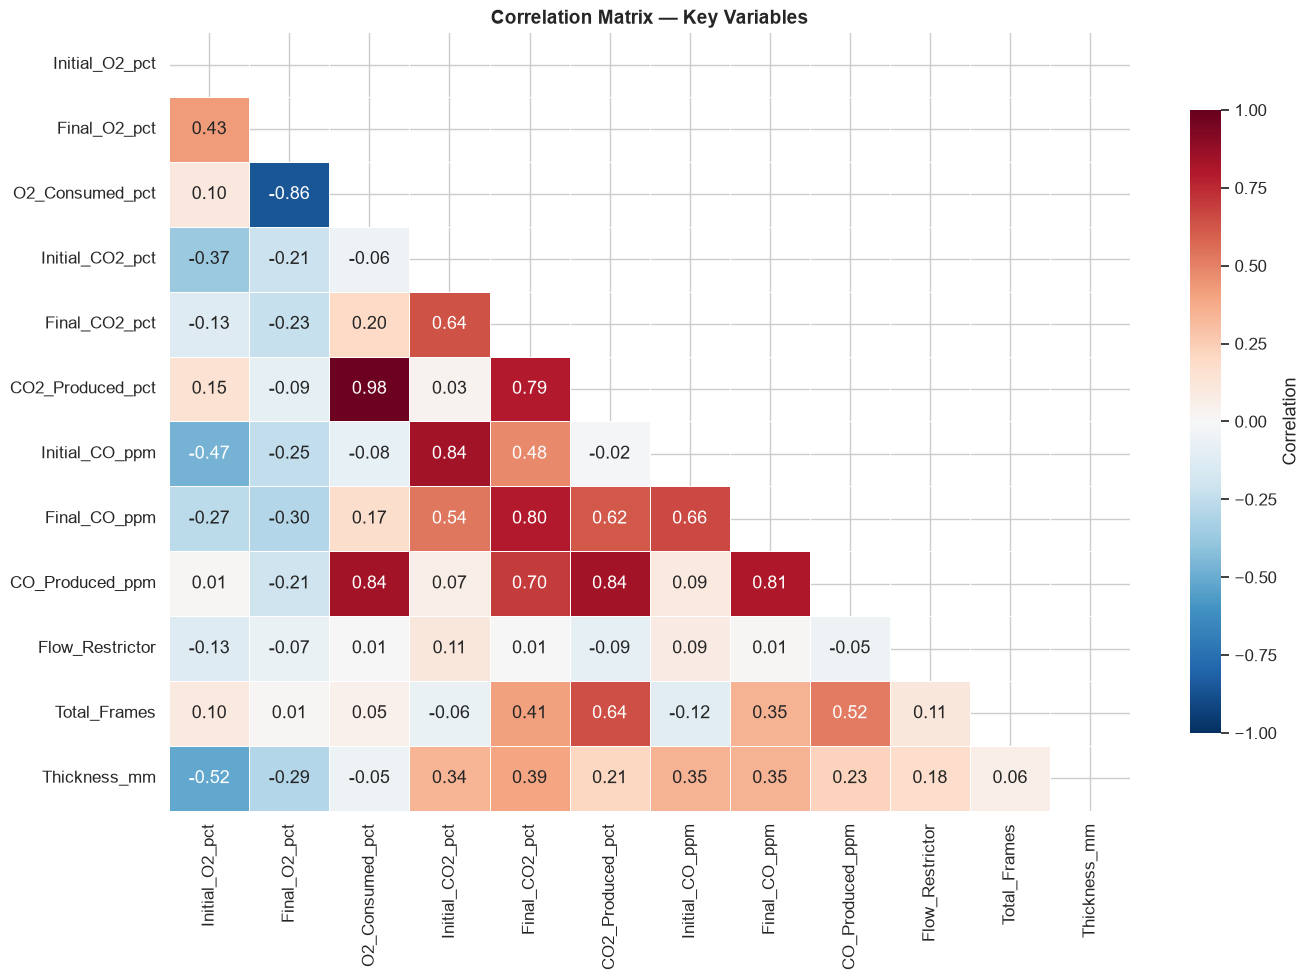

In [22]:
corr_cols = ['Initial_O2_pct', 'Final_O2_pct', 'O2_Consumed_pct',
             'Initial_CO2_pct', 'Final_CO2_pct', 'CO2_Produced_pct',
             'Initial_CO_ppm', 'Final_CO_ppm', 'CO_Produced_ppm',
             'Flow_Restrictor', 'Total_Frames', 'Thickness_mm']

corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(14, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            linewidths=0.5, linecolor='white', ax=ax, vmin=-1, vmax=1,
            cbar_kws={'label': 'Correlation', 'shrink': 0.8})
ax.set_title('Correlation Matrix — Key Variables')
plt.tight_layout()
plt.show()

## 14. Initial O₂ Impact on Combustion Products

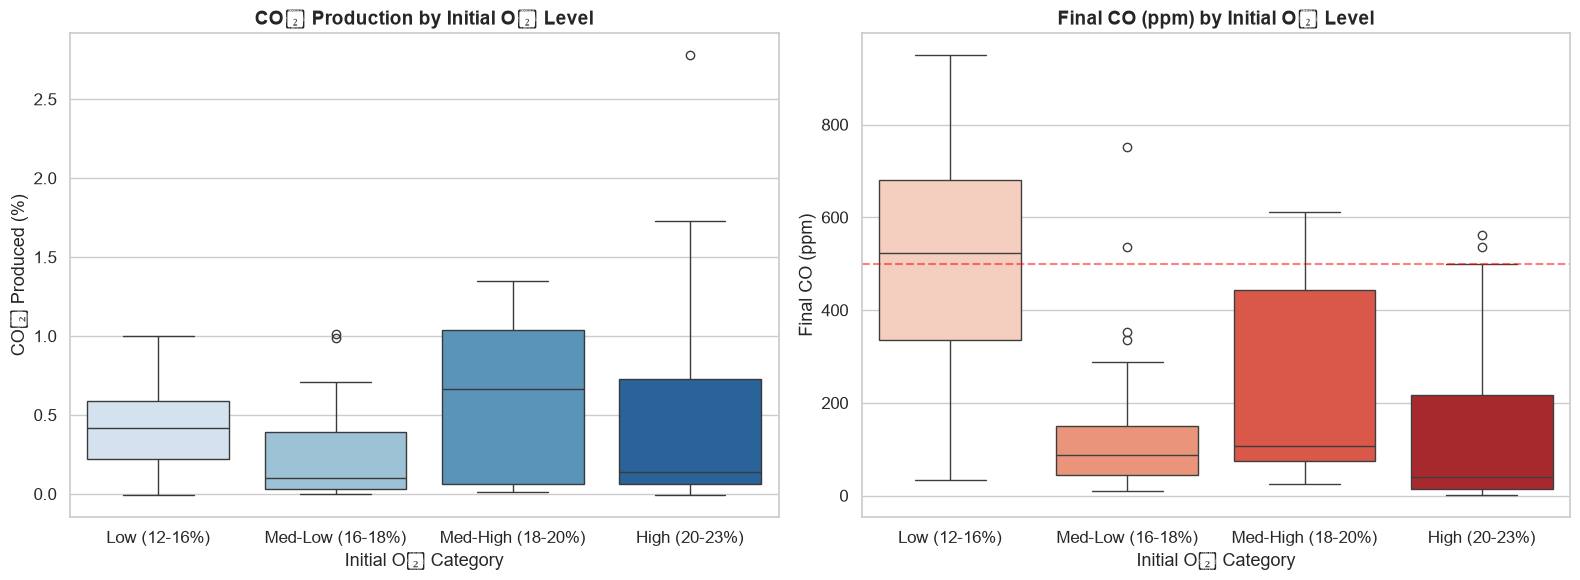

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bin initial O2 into categories
o2_bins = pd.cut(df['Initial_O2_pct'], bins=[12, 16, 18, 20, 23],
                 labels=['Low (12-16%)', 'Med-Low (16-18%)', 'Med-High (18-20%)', 'High (20-23%)'])
df_temp = df.copy()
df_temp['O2_Category'] = o2_bins

# CO2 by O2 category
sns.boxplot(data=df_temp.dropna(subset=['O2_Category', 'CO2_Produced_pct']),
            x='O2_Category', y='CO2_Produced_pct',
            palette='Blues', ax=axes[0])
axes[0].set_title('CO₂ Production by Initial O₂ Level')
axes[0].set_xlabel('Initial O₂ Category')
axes[0].set_ylabel('CO₂ Produced (%)')

# CO by O2 category
sns.boxplot(data=df_temp.dropna(subset=['O2_Category', 'Final_CO_ppm']),
            x='O2_Category', y='Final_CO_ppm',
            palette='Reds', ax=axes[1])
axes[1].set_title('Final CO (ppm) by Initial O₂ Level')
axes[1].set_xlabel('Initial O₂ Category')
axes[1].set_ylabel('Final CO (ppm)')
axes[1].axhline(500, color='red', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 15. Radiometer Gain Analysis

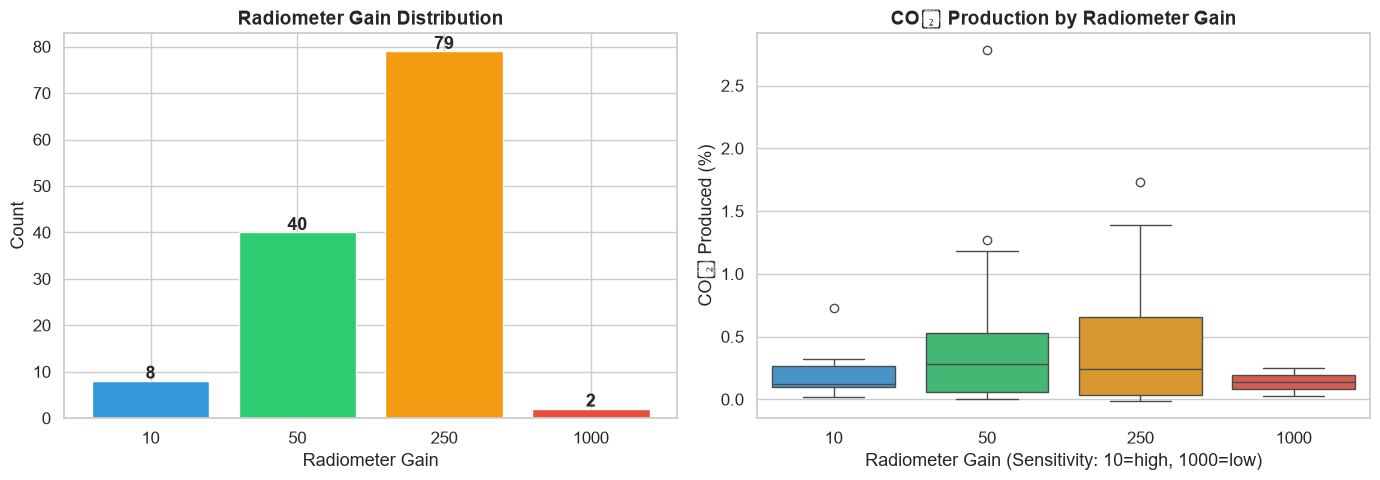

In [24]:
# Extract primary radiometer gain (first value if compound)
def extract_primary_gain(val):
    s = str(val).strip()
    # Handle compound like "250>50>250" or "250  50  250"
    m = re.match(r'(\d+)', s)
    if m:
        return int(m.group(1))
    return np.nan

df['Primary_Gain'] = df['Radiometer_Gain'].apply(extract_primary_gain)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gain distribution
gain_counts = df['Primary_Gain'].value_counts().sort_index()
gain_colors = {10: '#3498db', 50: '#2ecc71', 250: '#f39c12', 1000: '#e74c3c'}
bars = axes[0].bar([str(int(g)) for g in gain_counts.index],
                    gain_counts.values,
                    color=[gain_colors.get(g, '#95a5a6') for g in gain_counts.index],
                    edgecolor='white')
for bar, v in zip(bars, gain_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + 0.5, str(v),
                ha='center', fontweight='bold')
axes[0].set_xlabel('Radiometer Gain')
axes[0].set_ylabel('Count')
axes[0].set_title('Radiometer Gain Distribution')

# Gain vs CO2 produced
gain_data = df.dropna(subset=['Primary_Gain', 'CO2_Produced_pct'])
sns.boxplot(data=gain_data, x='Primary_Gain', y='CO2_Produced_pct',
            palette=[gain_colors.get(g, '#95a5a6') for g in sorted(gain_data['Primary_Gain'].unique())],
            ax=axes[1])
axes[1].set_title('CO₂ Production by Radiometer Gain')
axes[1].set_xlabel('Radiometer Gain (Sensitivity: 10=high, 1000=low)')
axes[1].set_ylabel('CO₂ Produced (%)')

plt.tight_layout()
plt.show()

## 16. Comprehensive Summary Dashboard

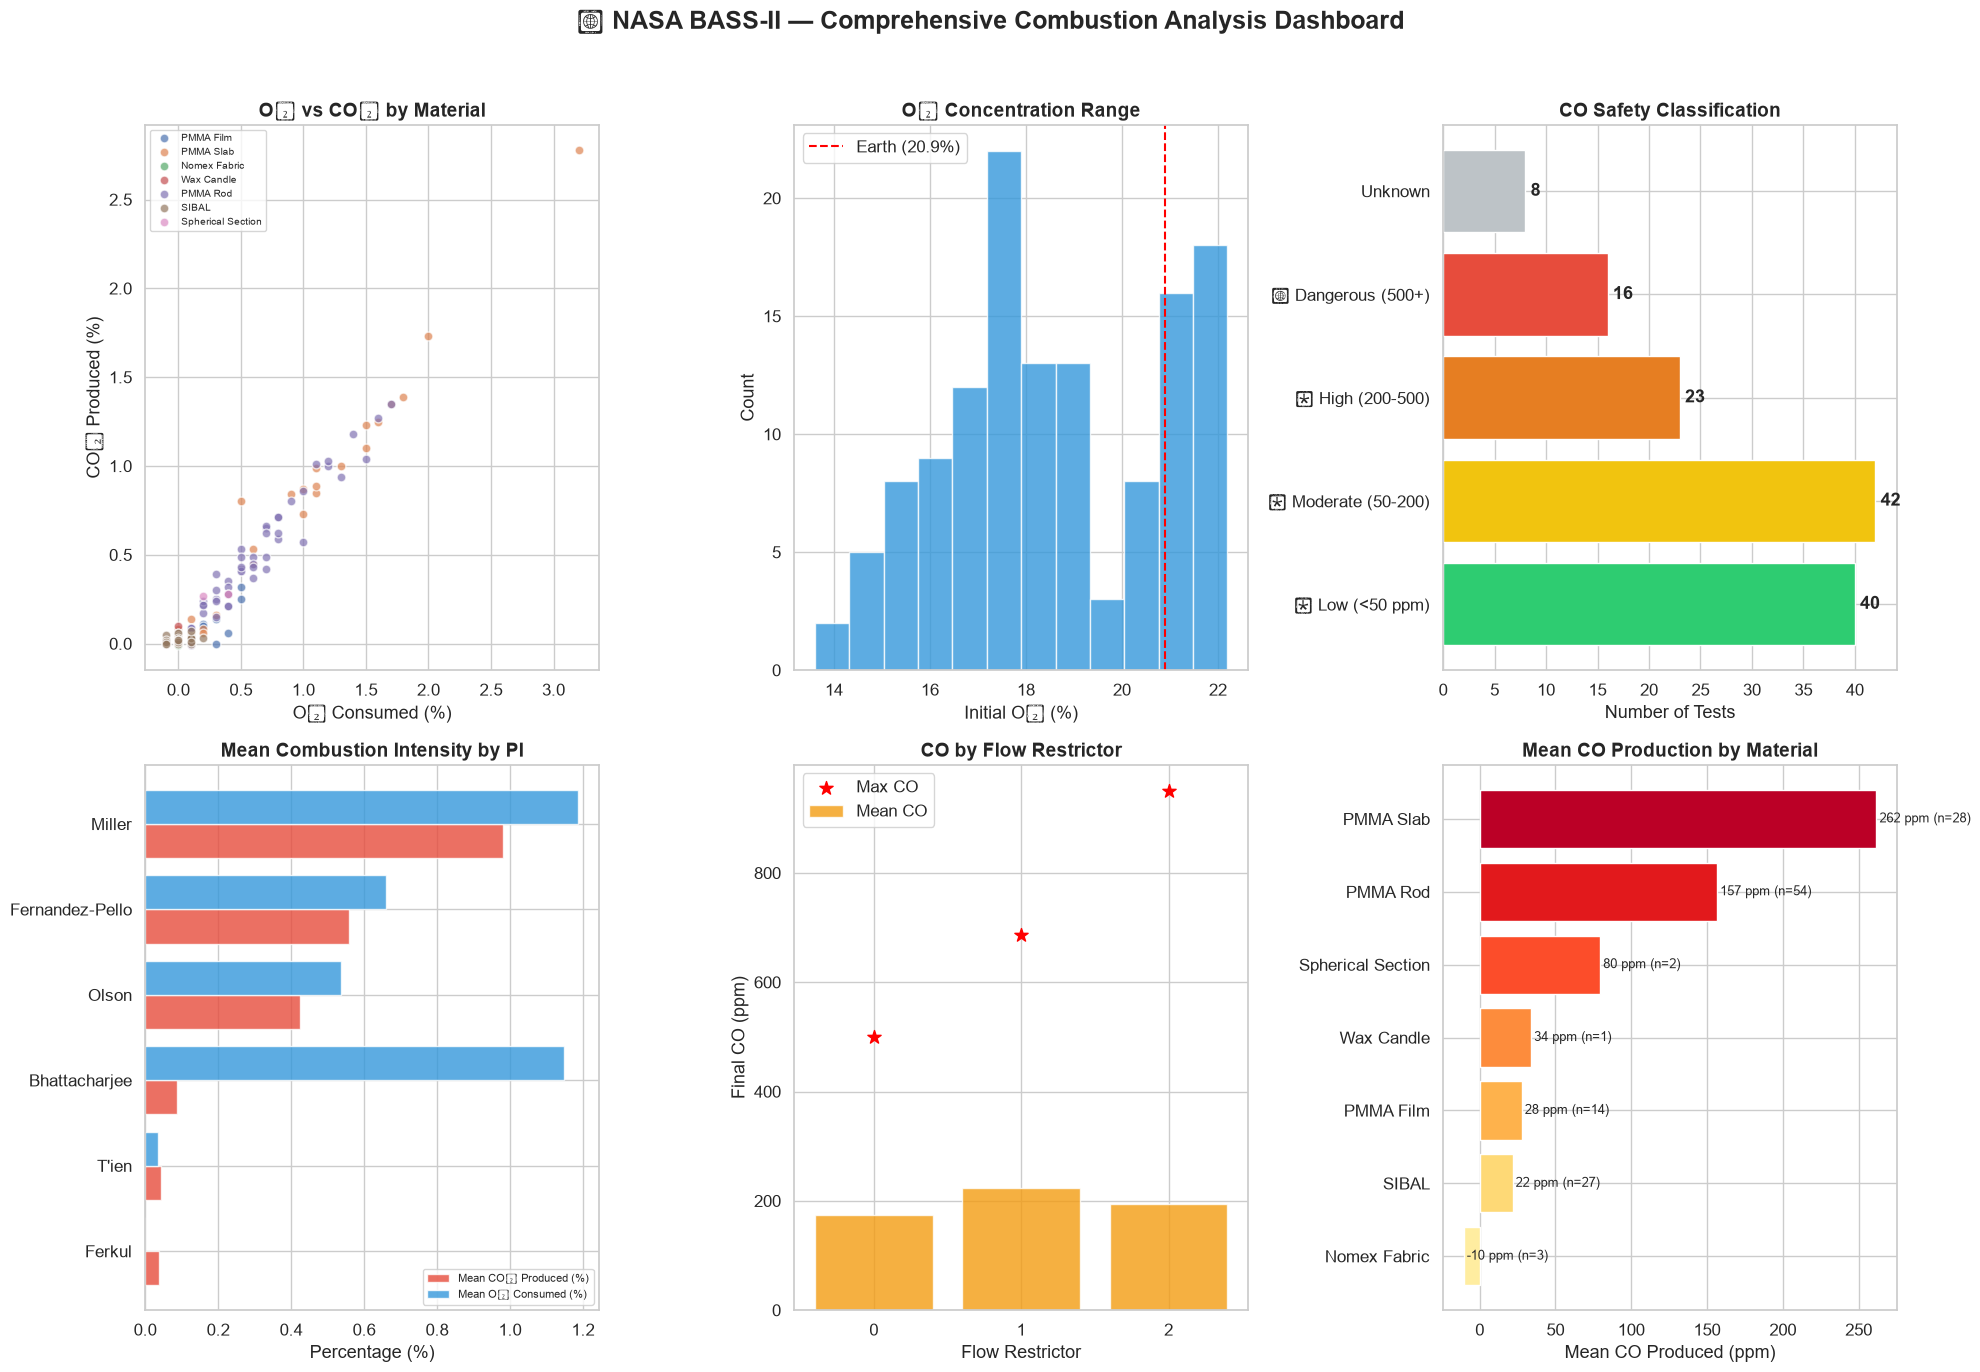

In [25]:
fig = plt.figure(figsize=(20, 14))
fig.suptitle('🔥 NASA BASS-II — Comprehensive Combustion Analysis Dashboard',
             fontsize=18, fontweight='bold', y=0.98)

# --- Panel 1: O2 consumed vs CO2 produced, colored by material ---
ax1 = fig.add_subplot(2, 3, 1)
mat_colors_map = dict(zip(df['Material_Category'].unique(),
                          sns.color_palette('Set2', df['Material_Category'].nunique())))
for mat in df['Material_Category'].unique():
    mask = df['Material_Category'] == mat
    ax1.scatter(df.loc[mask, 'O2_Consumed_pct'], df.loc[mask, 'CO2_Produced_pct'],
               label=mat, s=40, alpha=0.7, edgecolors='white')
ax1.set_xlabel('O₂ Consumed (%)')
ax1.set_ylabel('CO₂ Produced (%)')
ax1.set_title('O₂ vs CO₂ by Material')
ax1.legend(fontsize=7, loc='upper left')

# --- Panel 2: Initial O2 histogram ---
ax2 = fig.add_subplot(2, 3, 2)
ax2.hist(df['Initial_O2_pct'].dropna(), bins=12, color='#3498db',
         edgecolor='white', alpha=0.8)
ax2.axvline(20.9, color='red', linestyle='--', label='Earth (20.9%)')
ax2.set_xlabel('Initial O₂ (%)')
ax2.set_ylabel('Count')
ax2.set_title('O₂ Concentration Range')
ax2.legend()

# --- Panel 3: Danger level ---
ax3 = fig.add_subplot(2, 3, 3)
danger_order = ['🟢 Low (<50 ppm)', '🟡 Moderate (50-200)',
                '🟠 High (200-500)', '🔴 Dangerous (500+)', 'Unknown']
d_counts = df['CO_Danger_Level'].value_counts().reindex(danger_order).fillna(0)
d_colors = ['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c', '#bdc3c7']
bars = ax3.barh(d_counts.index, d_counts.values, color=d_colors, edgecolor='white')
for bar, v in zip(bars, d_counts.values):
    ax3.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             f'{int(v)}', va='center', fontweight='bold')
ax3.set_xlabel('Number of Tests')
ax3.set_title('CO Safety Classification')

# --- Panel 4: Mean gas production by PI ---
ax4 = fig.add_subplot(2, 3, 4)
pi_means = df.groupby('PI').agg({
    'O2_Consumed_pct': 'mean',
    'CO2_Produced_pct': 'mean',
}).sort_values('CO2_Produced_pct', ascending=True)

y_pos = range(len(pi_means))
ax4.barh(y_pos, pi_means['CO2_Produced_pct'], height=0.4,
         label='Mean CO₂ Produced (%)', color='#e74c3c', alpha=0.8)
ax4.barh([y + 0.4 for y in y_pos], pi_means['O2_Consumed_pct'], height=0.4,
         label='Mean O₂ Consumed (%)', color='#3498db', alpha=0.8)
ax4.set_yticks([y + 0.2 for y in y_pos])
ax4.set_yticklabels(pi_means.index)
ax4.set_xlabel('Percentage (%)')
ax4.set_title('Mean Combustion Intensity by PI')
ax4.legend(fontsize=8)

# --- Panel 5: Flow restrictor vs mean Final CO ---
ax5 = fig.add_subplot(2, 3, 5)
fr_stats = df.groupby('Flow_Restrictor')['Final_CO_ppm'].agg(['mean', 'std', 'max'])
fr_stats = fr_stats.dropna()
x_labels = [f'{int(x)}' for x in fr_stats.index]
ax5.bar(x_labels, fr_stats['mean'], color='#f39c12', edgecolor='white',
        alpha=0.8, label='Mean CO')
ax5.scatter(x_labels, fr_stats['max'], color='red', s=100, zorder=5,
            marker='*', label='Max CO')
ax5.set_xlabel('Flow Restrictor')
ax5.set_ylabel('Final CO (ppm)')
ax5.set_title('CO by Flow Restrictor')
ax5.legend()

# --- Panel 6: Material category summary ---
ax6 = fig.add_subplot(2, 3, 6)
mat_summary = df.groupby('Material_Category').agg({
    'Test_ID': 'count',
    'CO_Produced_ppm': 'mean',
    'CO2_Produced_pct': 'mean'
}).rename(columns={'Test_ID': 'N_Tests'})
mat_summary = mat_summary.sort_values('CO_Produced_ppm', ascending=True)

ax6.barh(mat_summary.index, mat_summary['CO_Produced_ppm'],
         color=sns.color_palette('YlOrRd', len(mat_summary)), edgecolor='white')
ax6.set_xlabel('Mean CO Produced (ppm)')
ax6.set_title('Mean CO Production by Material')
for i, (idx, row) in enumerate(mat_summary.iterrows()):
    if not np.isnan(row['CO_Produced_ppm']):
        ax6.text(row['CO_Produced_ppm'] + 2, i,
                 f'{row["CO_Produced_ppm"]:.0f} ppm (n={int(row["N_Tests"])})',
                 va='center', fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 17. Key Findings Summary

In [26]:
print('=' * 70)
print('     🔥 NASA BASS-II — KEY FINDINGS SUMMARY')
print('=' * 70)

print('\n📊 DATASET:')
print(f'   • {len(df)} combustion tests by {df["PI"].nunique()} PIs')
print(f'   • {df["Material_Category"].nunique()} material categories')
print(f'   • Date range: {df["Date"].min():%b %Y} – {df["Date"].max():%b %Y}')

print('\n🌬️ OXYGEN (O₂):')
print(f'   • Initial O₂ range: {df["Initial_O2_pct"].min():.1f}% – {df["Initial_O2_pct"].max():.1f}%')
print(f'   • Mean O₂ consumed: {df["O2_Consumed_pct"].mean():.2f}%')
print(f'   • Max O₂ consumed: {df["O2_Consumed_pct"].max():.2f}% (intense combustion)')

# Most CO2 producing PI
top_co2_pi = df.groupby('PI')['CO2_Produced_pct'].mean().idxmax()
print(f'\n💨 CO₂ PRODUCTION:')
print(f'   • Highest mean CO₂ producer: {top_co2_pi}')
print(f'   • Max CO₂ in single test: {df["CO2_Produced_pct"].max():.2f}%')

# Most dangerous
danger_count = (df['Final_CO_ppm'] >= 500).sum()
print(f'\n⚠️ CO SAFETY:')
print(f'   • Tests with CO ≥ 500 ppm (DANGEROUS): {danger_count}')
print(f'   • Tests with CO ≥ 200 ppm (HIGH):      {(df["Final_CO_ppm"] >= 200).sum()}')
print(f'   • Max CO recorded: {df["Final_CO_ppm"].max():.0f} ppm')
top_co_test = df.loc[df['Final_CO_ppm'].idxmax()]
print(f'   • Most dangerous test: {top_co_test["Test_ID"]} '
      f'({top_co_test["PI"]}, {top_co_test["Material_Category"]})')

# Material insights
print(f'\n🧱 MATERIAL INSIGHTS:')
for mat in df.groupby('Material_Category')['CO_Produced_ppm'].mean().sort_values(ascending=False).index:
    n = (df['Material_Category'] == mat).sum()
    mean_co = df.loc[df['Material_Category'] == mat, 'CO_Produced_ppm'].mean()
    if not np.isnan(mean_co):
        print(f'   • {mat:20s}: mean CO = {mean_co:6.1f} ppm  (n={n})')

print(f'\n🔑 KEY TAKEAWAY:')
print(f'   Thicker PMMA materials (slabs & rods) produce significantly')
print(f'   more CO in microgravity — a critical fire safety concern for')
print(f'   spacecraft design and material selection!')
print('=' * 70)

     🔥 NASA BASS-II — KEY FINDINGS SUMMARY

📊 DATASET:
   • 129 combustion tests by 6 PIs
   • 7 material categories
   • Date range: Feb 2014 – Jun 2018

🌬️ OXYGEN (O₂):
   • Initial O₂ range: 13.6% – 22.2%
   • Mean O₂ consumed: 0.64%
   • Max O₂ consumed: 20.60% (intense combustion)

💨 CO₂ PRODUCTION:
   • Highest mean CO₂ producer: Miller
   • Max CO₂ in single test: 2.78%

⚠️ CO SAFETY:
   • Tests with CO ≥ 500 ppm (DANGEROUS): 16
   • Tests with CO ≥ 200 ppm (HIGH):      39
   • Max CO recorded: 950 ppm
   • Most dangerous test: O13a (Olson, PMMA Rod)

🧱 MATERIAL INSIGHTS:
   • PMMA Slab           : mean CO =  261.7 ppm  (n=28)
   • PMMA Rod            : mean CO =  156.7 ppm  (n=54)
   • Spherical Section   : mean CO =   79.5 ppm  (n=2)
   • Wax Candle          : mean CO =   34.0 ppm  (n=1)
   • PMMA Film           : mean CO =   27.8 ppm  (n=14)
   • SIBAL               : mean CO =   21.7 ppm  (n=27)
   • Nomex Fabric        : mean CO =  -10.5 ppm  (n=3)

🔑 KEY TAKEAWAY:
   Thick

In [27]:
# Save cleaned dataset
output_path = 'BASS_II_cleaned.csv'
export_cols = ['PI', 'Test_ID', 'Date', 'GMT', 'Sample_No', 'Fuel_Material',
               'Material_Category', 'Thickness_mm', 'Flow_Restrictor',
               'Total_Frames', 'Initial_O2_pct', 'Final_O2_pct', 'O2_Consumed_pct',
               'Initial_CO2_pct', 'Final_CO2_pct', 'CO2_Produced_pct',
               'Initial_CO_ppm', 'Final_CO_ppm', 'CO_Produced_ppm', 'CO_Danger_Level']
df[export_cols].to_csv(output_path, index=False)
print(f'✅ Cleaned dataset saved to: {output_path}')
print(f'   Shape: {df[export_cols].shape}')

✅ Cleaned dataset saved to: BASS_II_cleaned.csv
   Shape: (129, 20)
